In [3]:
import pandas as pd
import numpy as np

In [4]:
data = "wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
!wget $data

--2026-10-22 09:32:25--  http://wget/
Resolving wget (wget)... failed: Name or service not known.
wget: unable to resolve host address ‘wget’
--2026-10-22 09:32:25--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.8’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.06s   

2026-10-22 09:32:25 (4.26 MB/s) - ‘course_lead_scoring_2026.csv.8’ saved [278746/278746]

FINISHED --2026-10-22 09:32:25--
Total wall clock time: 0.6s
Downloaded: 1 files, 272K in 0.06s (4.26 MB/s)


In [5]:
df = pd.read_csv("course_lead_scoring_2026.csv")

In [6]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [7]:
print(df.shape)

(5000, 9)


In [8]:
print(df.isnull().sum())

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [9]:
# Separate features from the target
X = df.drop(columns=["converted"])
y = df["converted"]

# Identify categorical features
categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns

# Identify numerical features
numerical_features = X.select_dtypes(
    include="number"
).columns

print("Categorical features:")
print(list(categorical_features))

print("\nNumerical features:")
print(list(numerical_features))

Categorical features:
['lead_source', 'industry', 'employment_status', 'location']

Numerical features:
['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [10]:
X.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
dtype: int64

In [11]:
X[categorical_features] = X[categorical_features].fillna("NA")
X[numerical_features] = X[numerical_features].fillna(0.0)

In [12]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [13]:
from sklearn.metrics import roc_auc_score

In [14]:
numerical_features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

auc_scores = {}

for feature in numerical_features:
    scores = df_train[feature].fillna(0.0)

    auc = roc_auc_score(df_train["converted"], scores)

    if auc < 0.5:
        auc = roc_auc_score(df_train["converted"], -scores)

    auc_scores[feature] = auc

sorted(auc_scores.items(), key=lambda x: x[1], reverse=True)

[('lead_score', 0.7882254810906102),
 ('interaction_count', 0.7649203047563227),
 ('number_of_courses_viewed', 0.7229894623989618),
 ('annual_income', 0.6081977776250831)]

In [15]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

y_train = df_train["converted"].values
y_val = df_val["converted"].values

del df_train["converted"]
del df_val["converted"]

train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [16]:
train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

In [17]:
from sklearn.feature_extraction import DictVectorizer
import numpy as np

train_dicts = [
    {k: (0.0 if isinstance(v, float) and np.isnan(v) else v)
     for k, v in row.items()}
    for row in train_dicts
]

val_dicts = [
    {k: (0.0 if isinstance(v, float) and np.isnan(v) else v)
     for k, v in row.items()}
    for row in val_dicts
]

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [18]:
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

round(roc_auc_score(y_val, y_pred), 3)

0.732

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for threshold in thresholds:
    y_pred_binary = (y_pred >= threshold).astype(int)

    precisions.append(precision_score(y_val, y_pred_binary, zero_division=0))
    recalls.append(recall_score(y_val, y_pred_binary, zero_division=0))

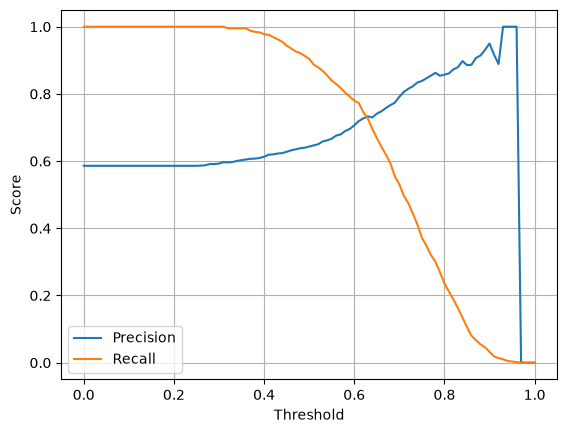

In [20]:
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

In [21]:
precisions = np.array(precisions)
recalls = np.array(recalls)

difference = np.abs(precisions - recalls)
valid = (precisions != 0) | (recalls != 0)

best_index = np.argmin(np.where(valid, difference, np.inf))

thresholds[best_index], precisions[best_index], recalls[best_index]

(np.float64(0.63),
 np.float64(0.7332185886402753),
 np.float64(0.726962457337884))

In [22]:
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

In [23]:
best_index = np.argmax(f1_scores)

thresholds[best_index], f1_scores[best_index]

(np.float64(0.41000000000000003), np.float64(0.7576158939922404))

In [24]:
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_fold_train = df_full_train.iloc[train_idx].copy()
    df_fold_val = df_full_train.iloc[val_idx].copy()

    y_fold_train = df_fold_train.pop("converted").values
    y_fold_val = df_fold_val.pop("converted").values

    train_dicts = df_fold_train.to_dict(orient="records")
    val_dicts = df_fold_val.to_dict(orient="records")

    # Replace missing numeric values with 0
    train_dicts = [
        {k: (0.0 if isinstance(v, float) and np.isnan(v) else v)
         for k, v in row.items()}
        for row in train_dicts
    ]
    val_dicts = [
        {k: (0.0 if isinstance(v, float) and np.isnan(v) else v)
         for k, v in row.items()}
        for row in val_dicts
    ]

    dv_fold = DictVectorizer(sparse=False)
    X_fold_train = dv_fold.fit_transform(train_dicts)
    X_fold_val = dv_fold.transform(val_dicts)

    model_fold = LogisticRegression(
        solver="liblinear",
        C=1.0,
        max_iter=1000
    )
    model_fold.fit(X_fold_train, y_fold_train)

    y_fold_pred = model_fold.predict_proba(X_fold_val)[:, 1]
    auc = roc_auc_score(y_fold_val, y_fold_pred)
    scores.append(auc)

scores

[0.7305344246509389,
 0.7297441533936047,
 0.7363492431263516,
 0.741302972802024,
 0.7210430446465481]

In [25]:
np.std(scores)

np.float64(0.00681971030065697)

In [28]:
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
C_values = [0.000001, 0.001, 1]

for C in C_values:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx].copy()
        df_fold_val = df_full_train.iloc[val_idx].copy()

        y_fold_train = df_fold_train.pop("converted").values
        y_fold_val = df_fold_val.pop("converted").values

        train_dicts = df_fold_train.to_dict(orient="records")
        val_dicts = df_fold_val.to_dict(orient="records")

        train_dicts = [
            {k: (0.0 if isinstance(v, float) and np.isnan(v) else v)
             for k, v in row.items()}
            for row in train_dicts
        ]

        val_dicts = [
            {k: (0.0 if isinstance(v, float) and np.isnan(v) else v)
             for k, v in row.items()}
            for row in val_dicts
        ]

        dv_fold = DictVectorizer(sparse=False)
        X_fold_train = dv_fold.fit_transform(train_dicts)
        X_fold_val = dv_fold.transform(val_dicts)

        model_fold = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000
        )

        model_fold.fit(X_fold_train, y_fold_train)

        y_fold_pred = model_fold.predict_proba(X_fold_val)[:, 1]
        scores.append(roc_auc_score(y_fold_val, y_fold_pred))

    print(
        f"C={C}: mean AUC={np.mean(scores):.3f}, "
        f"std={np.std(scores):.3f}"
    )

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007


In [30]:
for C in [0.000001, 0.001, 1]:

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        df_train = df_full_train.iloc[train_idx].copy()
        df_val = df_full_train.iloc[val_idx].copy()

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        del df_train['converted']
        del df_val['converted']

        # Handle missing values
        df_train = df_train.fillna(0)
        df_val = df_val.fillna(0)

        train_dicts = df_train.to_dict(orient="records")
        val_dicts = df_val.to_dict(orient="records")

        dv = DictVectorizer(sparse=False)

        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]

        auc = roc_auc_score(y_val, y_pred)

        scores.append(auc)

    print(
        f"C={C}: Mean AUC={np.mean(scores):.3f}, "
        f"Std={np.std(scores):.3f}"
    )

C=1e-06: Mean AUC=0.617, Std=0.019
C=0.001: Mean AUC=0.749, Std=0.010
C=1: Mean AUC=0.732, Std=0.007
